In [ ]:
#ДЗ 5
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

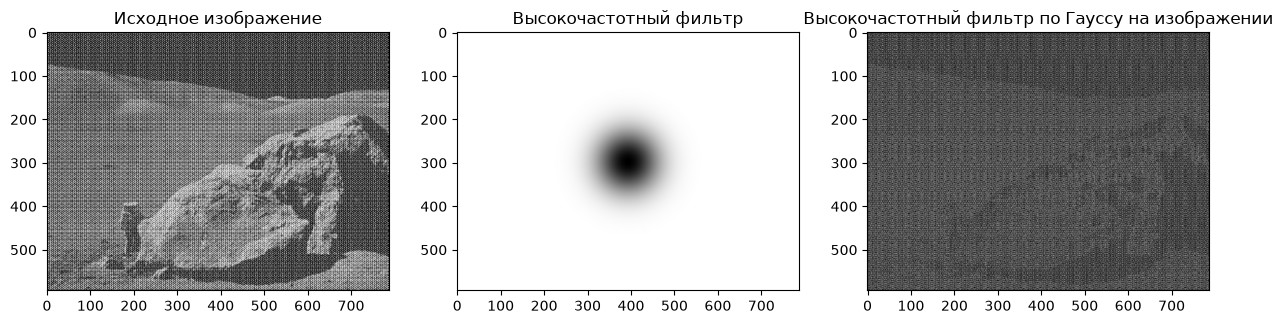

In [3]:
#1
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
    
rows, cols = img.shape
x, y = np.ogrid[:rows, :cols]
center_x, center_y = rows // 2, cols // 2
    
distance = np.sqrt((x - center_x)**2 + (y - center_y)**2)
    
sigma = 50
gaussian_lowpass = np.exp(-(distance**2) / (2 * (sigma**2)))
gaussian_highpass = 1 - gaussian_lowpass
    
mask = np.zeros((rows, cols, 2), np.float32)
mask[:,:,0] = gaussian_highpass
mask[:,:,1] = gaussian_highpass
    
dft_shift_filtered = dft_shift * mask
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

img_back = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

highpass_result, gaussian_mask = img_back, gaussian_highpass

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1);
plt.title('Исходное изображение')
plt.imshow(img, cmap='gray')

plt.subplot(1, 3, 2);
plt.title('Высокочастотный фильтр')
plt.imshow(gaussian_mask, cmap='gray')

plt.subplot(1, 3, 3);
plt.title('Высокочастотный фильтр по Гауссу на изображении')
plt.imshow(highpass_result, cmap='gray')

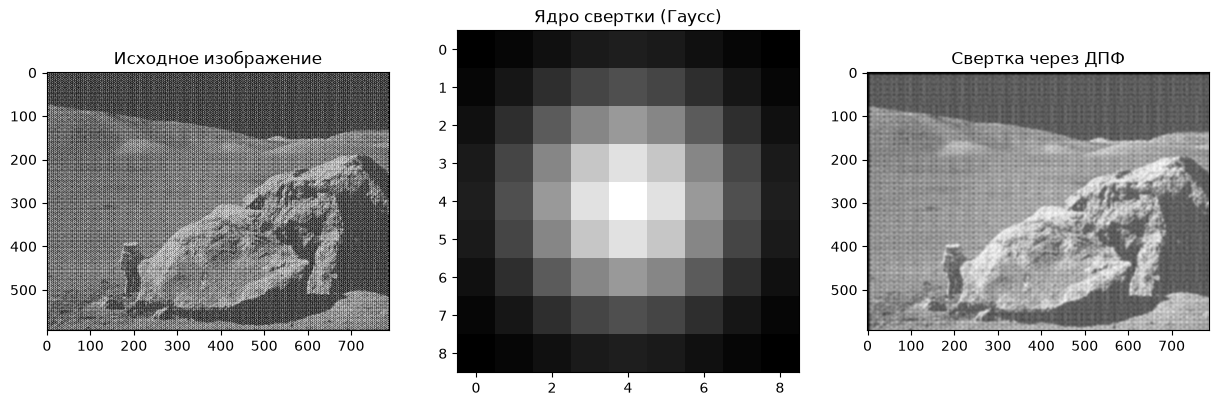

In [4]:
#2
kernel = cv.getGaussianKernel(9, 2)
kernel = np.outer(kernel, kernel)

k_rows, k_cols = kernel.shape

pad_rows = rows + k_rows - 1
pad_cols = cols + k_cols - 1

img_padded = np.pad(img, ((0, pad_rows - rows), (0, pad_cols - cols)), mode='constant')
kernel_padded = np.pad(kernel, ((0, pad_rows - k_rows), (0, pad_cols - k_cols)), mode='constant')

dft_img = cv.dft(np.float32(img_padded), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(np.float32(kernel_padded), flags=cv.DFT_COMPLEX_OUTPUT)

dft_conv = cv.mulSpectrums(dft_img, dft_kernel, 0)

img_back = cv.idft(dft_conv)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

img_back = img_back[:rows, :cols]
conv_result = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Исходное изображение')
plt.imshow(img, cmap='gray')

plt.subplot(1, 3, 2)
plt.title('Ядро свертки (Гаусс)')
plt.imshow(kernel, cmap='gray')

plt.subplot(1, 3, 3)
plt.title('Свертка через ДПФ')
plt.imshow(conv_result, cmap='gray')

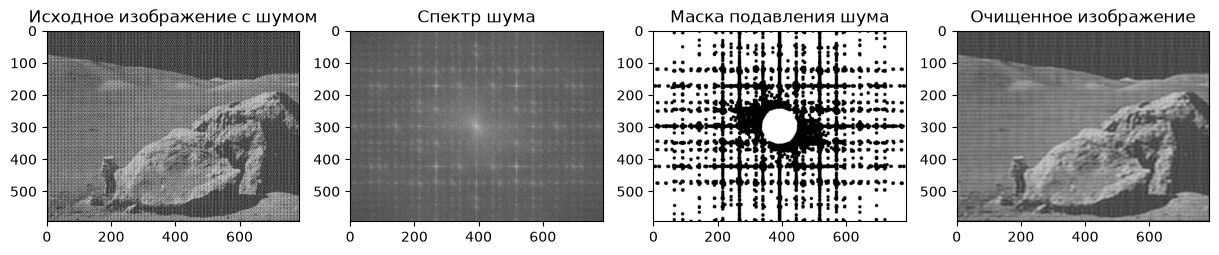

In [9]:
#3
magnitude = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1e-5)
magnitude_norm = cv.normalize(magnitude, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

_, thresh = cv.threshold(magnitude_norm, np.percentile(magnitude_norm, 96), 255, cv.THRESH_BINARY)
peaks = cv.findNonZero(thresh)

notch_mask = np.ones((rows, cols), dtype=np.float32)
r = 5
center_radius = min(rows, cols) // 10

x, y = np.ogrid[:rows, :cols]

if peaks is not None:
    for pt in peaks:
        px, py = pt.ravel()
        
        if (py - center_x)**2 + (px - center_y)**2 < center_radius**2:
            continue
            
        dist_from_peak = np.sqrt((x - py)**2 + (y - px)**2)
        notch_mask[dist_from_peak <= r] = 0

mask = np.zeros((rows, cols, 2), np.float32)
mask[:, :, 0] = notch_mask
mask[:, :, 1] = notch_mask

dft_shift_filtered = dft_shift * mask

f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

denoised_result = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.title('Исходное изображение с шумом')
plt.imshow(img, cmap='gray')

plt.subplot(1, 4, 2)
plt.title('Спектр шума')
plt.imshow(magnitude, cmap='gray')

plt.subplot(1, 4, 3)
plt.title('Маска подавления шума')
plt.imshow(notch_mask, cmap='gray')

plt.subplot(1, 4, 4)
plt.title('Очищенное изображение')
plt.imshow(denoised_result, cmap='gray')